# Preset and definition of variables

In [19]:
import os

import mne_nirs
import mne_nirs.io
from mne_nirs.channels import (get_long_channels,
                               get_short_channels,
                               picks_pair_to_idx)



import mne
import mne.io

import pandas as pd

import numpy as np

import matplotlib.pyplot as plt

from nilearn.glm.first_level import make_first_level_design_matrix

%matplotlib inline 

Download data for the creation of surface images.

In [20]:
# Download anatomical locations
subjects_dir = os.path.join(mne.datasets.sample.data_path(), 'subjects')
mne.datasets.fetch_fsaverage(subjects_dir=subjects_dir)


0 files missing from root.txt in /Users/brunoleitao/mne_data/MNE-sample-data/subjects
0 files missing from bem.txt in /Users/brunoleitao/mne_data/MNE-sample-data/subjects/fsaverage


PosixPath('/Users/brunoleitao/mne_data/MNE-sample-data/subjects/fsaverage')

# 0. Select data

Select data in the BIDS format. Set the root to the folder and number of the run.

In [32]:
# Participant id.
p_id = '000'

# Session id.
session_id = '01'

# Run id.
run_id = '1'

# task id.
task_id = 'dm'

# write data_path using p_id.
data_path = os.path.join('..', 'data', f'sub-{p_id}', 'nirs', f'sub-{p_id}_ses-{session_id}_tk-{task_id}_run-{run_id}_nirs_{p_id}')

print(data_path)

../data/sub-000/nirs/sub-000_ses-01_tk-dm_run-1_nirs_000


Get snirf file for participant 'p_id' and run 'run_id'. Load data to the raw_intensity variable.

In [33]:
# Create an empty list to store the raw intensity data
raw_intensity = []

# Get files with .snirf extension using os
snirf_files = [os.path.join(data_path, f) for f in os.listdir(data_path) if f.endswith('.snirf')]

# select file that contains run_id in its name
snirf_file = [f for f in snirf_files if run_id in f]

if snirf_file:
    # Load the data in snirf_file
    raw_intensity = mne.io.read_raw_snirf(snirf_file[0], preload=True)

    raw_intensity.load_data()

else:
    
    print('No snirf file found')



Loading /Users/brunoleitao/Documents/GitHub/NIRS-UC-UMAD/scripts/../data/sub-000/nirs/sub-000_ses-01_tk-dm_run-1_nirs_000/sub-000_ses-01_tk-dm_run-1_nirs_000.snirf
Found jitter of 0.000000% in sample times.
Reading 0 ... 4808  =      0.000 ...   472.646 secs...


In [34]:
# mne.io.read_raw_snirf(snirf_file[0], preload=True)

snirf_file[0]

'../data/sub-000/nirs/sub-000_ses-01_tk-dm_run-1_nirs_000/sub-000_ses-01_tk-dm_run-1_nirs_000.snirf'

# 1. Annotations, check for types of triggers and renaming

The triggers codes correspondence: "1": "Baseline", "2": "Q1", "3": "Q2", "4": "Q3", "5": "Q4", "8": "Begin", "9": "End"


In [35]:
# t_max = lsat moment of the recording
tmax = [] 
tmax.append( raw_intensity.times[-1] )

print(tmax)

[np.float64(472.6456319999999)]


In [36]:
raw_intensity.annotations

# unique annotations
raw_intensity.annotations.description

# reset duration of conditions
raw_intensity.annotations.set_durations(2)


<Annotations | 42 segments: 100 (1), 110 (10), 120 (10), 130 (10), 150 ...>

In [37]:
# get the time difference between two consecutive annotations
for i in range(len(raw_intensity.annotations.description)-1):
    print(raw_intensity.annotations.description[i], raw_intensity.annotations.description[i+1], raw_intensity.annotations.onset[i+1] - raw_intensity.annotations.onset[i])

    # set the duration of the videos
    if raw_intensity.annotations.description[i] == '120':
        raw_intensity.annotations.duration[i] = raw_intensity.annotations.onset[i+1] - raw_intensity.annotations.onset[i]

100 110 27.602733999999998
110 120 9.181044
120 130 26.757618000000008
130 150 1.1854510000000005
150 110 2.5045729999999935
110 120 10.917252999999988
120 130 21.915362000000016
130 150 1.1137379999999837
150 110 2.49693400000001
110 120 8.958792000000017
120 130 20.199791999999974
130 150 0.8322510000000136
150 110 2.4974510000000123
110 120 8.942491999999987
120 130 15.90135699999999
130 150 3.08262400000001
150 110 2.4972649999999987
110 120 10.92709099999999
120 130 17.946224
130 150 1.484059000000002
150 110 2.4979490000000055
110 120 10.826925000000017
120 130 20.77692300000001
130 150 1.052170999999987
150 110 2.480156999999963
110 120 10.874481000000003
120 130 29.88683000000003
130 150 3.016711999999984
150 110 2.515036000000009
110 120 10.973770000000002
120 130 25.292269999999974
130 150 0.9511400000000094
150 110 2.4984130000000278
110 120 10.785402999999974
120 130 21.982709999999997
130 150 0.9682870000000321
150 110 2.4989949999999794
110 120 8.825535000000002
120 130 1

In [38]:
raw_intensity.annotations.duration

array([ 2.      ,  2.      , 26.757618,  2.      ,  2.      ,  2.      ,
       21.915362,  2.      ,  2.      ,  2.      , 20.199792,  2.      ,
        2.      ,  2.      , 15.901357,  2.      ,  2.      ,  2.      ,
       17.946224,  2.      ,  2.      ,  2.      , 20.776923,  2.      ,
        2.      ,  2.      , 29.88683 ,  2.      ,  2.      ,  2.      ,
       25.29227 ,  2.      ,  2.      ,  2.      , 21.98271 ,  2.      ,
        2.      ,  2.      , 16.049979,  2.      ,  2.      ,  2.      ])

In [39]:


# rename conditions
# raw_intensity.annotations.rename( {"1": "Baseline","2": "Q1","3": "Q2", "4": "Q3", "5": "Q4", "8": "Begin","9": "End"} )

raw_intensity.annotations.rename( {"120": "Video",
                                    "100": "init",
                                    "160": "end"} 
                                )





<Annotations | 42 segments: 110 (10), 130 (10), 150 (10), Video (10), end ...>

In [40]:
raw_intensity.annotations[-1]

OrderedDict([('onset', np.float64(440.202764)),
             ('duration', np.float64(2.0)),
             ('description', np.str_('end')),
             ('orig_time',
              datetime.datetime(2026, 7, 24, 14, 50, 57, tzinfo=datetime.timezone.utc)),
             ('extras', {})])

**Crop data considering begin and end triggers.**

Get onset for the trigger init and end. Crop data on these markers. Remove annotations outside this period from the data structure.


In [41]:
# Trim Data
tmin = raw_intensity.annotations[raw_intensity.annotations.description == "init"].onset


tmax = raw_intensity.annotations[raw_intensity.annotations.description == "end"].onset

timeatorigin = raw_intensity.annotations.orig_time

print(timeatorigin, tmin, tmax)

dur = tmax-tmin
print (dur)

duration_min=dur/60
print (duration_min)


2026-07-24 14:50:57+00:00 [53.807677] [440.202764]
[386.395087]
[6.43991812]


In [186]:
# import datetime 

# deltamin = datetime.timedelta(seconds=tmin[0] + 1)   
# deltamax = datetime.timedelta(seconds=tmax[0] + 1) 

# annots = raw_intensity.annotations.crop( timeatorigin + deltamin, timeatorigin + deltamax, use_orig_time=False )


In [42]:
# Remove annotations outside of the trimmed data
raw_intensity.annotations.delete(raw_intensity.annotations.onset <= tmin[0])
raw_intensity.annotations.delete(raw_intensity.annotations.onset >= tmax[0])

In [43]:
raw_intensity.crop( tmin[0], tmax[0] )



<RawSNIRF | sub-000_ses-01_tk-dm_run-1_nirs_000.snirf, 56 x 3932 (386.5 s), ~1.8 MiB, data loaded>

# 2. Conversion from CW to haemoglobin data.

In [44]:
# Convert NIRS raw data to optical density.
raw_od = mne.preprocessing.nirs.optical_density(raw_intensity)


[Text(0.5, 0, 'Scalp Coupling Index'), Text(0, 0.5, 'Count'), (0.0, 1.0)]

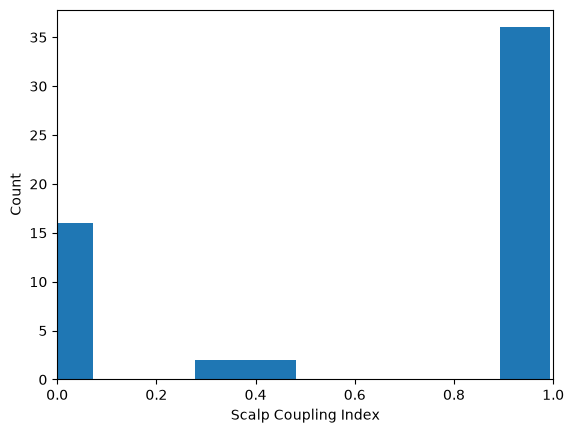

In [45]:
# TODO: https://mne.tools/mne-nirs/stable/auto_examples/general/plot_22_quality.html

sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od)
fig, ax = plt.subplots()
ax.hist(sci)
ax.set(xlabel='Scalp Coupling Index', ylabel='Count', xlim=[0, 1])

We can mark these as bad in the MNE data. This way the functions downstream will know that the data in these channels is bad. For this example we set the threshold for a bad channel to be SCI < 0.7. We then print a list of the bad channels.

['S1_D8 760', 'S2_D9 760', 'S3_D2 760', 'S3_D10 760', 'S4_D11 760', 'S5_D12 760', 'S6_D5 760', 'S6_D13 760', 'S7_D14 760', 'S8_D15 760', 'S1_D8 850', 'S2_D9 850', 'S3_D2 850', 'S3_D10 850', 'S4_D11 850', 'S5_D12 850', 'S6_D5 850', 'S6_D13 850', 'S7_D14 850', 'S8_D15 850']


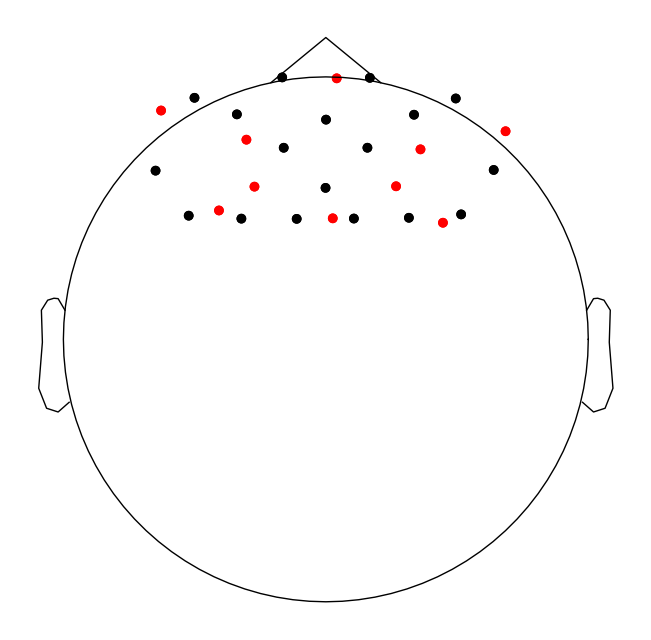

In [46]:
# Select raw_od channels with sci < 0.7

from itertools import compress


raw_od.info['bads'] = list(compress(raw_od.ch_names, sci < 0.7))
print(raw_od.info['bads'])

raw_od.plot_sensors();

### Temporal Derivative Distribution Repair (TDDR)
TDDR was initially designed to be used on optical density fNIRS data but has been enabled to be applied on hemoglobin concentration fNIRS data as well in MNE. We recommend applying the algorithm to optical density fNIRS data as intended by the original author wherever possible.

There is a shorter alias mne.preprocessing.nirs.tddr that can be used instead of this function (e.g. if line length is an issue).

In [47]:
raw_tddr_od = mne.preprocessing.nirs.tddr(raw_od)


In [48]:

# Convert optical density data to haemoglobin data (ppf - The partial pathlength factor).
raw_haemo = mne.preprocessing.nirs.beer_lambert_law(raw_tddr_od, ppf=6.0)


## 2.1 Preprocessing

In [49]:
raw_haemo = raw_haemo.filter(None, 
                             0.5, 
                             h_trans_bandwidth=0.5,
                             l_trans_bandwidth=0.01)


Filtering raw data in 1 contiguous segment
Setting up low-pass filter at 0.5 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal lowpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Upper passband edge: 0.50 Hz
- Upper transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.75 Hz)
- Filter length: 69 samples (6.783 s)



## 2.2 Channel selection

In [50]:
# Return channels with a long source detector separation.
short_haemo = mne_nirs.channels.get_short_channels(raw_haemo, max_dist=0.01)

# Return channels with a long source detector separation.
long_haemo = mne_nirs.channels.get_long_channels(raw_haemo)

In [51]:
mne_nirs.channels.list_sources(long_haemo)
print(long_haemo.ch_names)

['S1_D1 hbo', 'S1_D2 hbo', 'S2_D1 hbo', 'S2_D3 hbo', 'S3_D3 hbo', 'S3_D4 hbo', 'S4_D2 hbo', 'S4_D4 hbo', 'S4_D5 hbo', 'S5_D3 hbo', 'S5_D4 hbo', 'S5_D6 hbo', 'S6_D4 hbo', 'S6_D6 hbo', 'S7_D5 hbo', 'S7_D7 hbo', 'S8_D6 hbo', 'S8_D7 hbo', 'S1_D1 hbr', 'S1_D2 hbr', 'S2_D1 hbr', 'S2_D3 hbr', 'S3_D3 hbr', 'S3_D4 hbr', 'S4_D2 hbr', 'S4_D4 hbr', 'S4_D5 hbr', 'S5_D3 hbr', 'S5_D4 hbr', 'S5_D6 hbr', 'S6_D4 hbr', 'S6_D6 hbr', 'S7_D5 hbr', 'S7_D7 hbr', 'S8_D6 hbr', 'S8_D7 hbr']


In [52]:
len(long_haemo.ch_names)

36

# 3. GLM analysis

## 3.1 design matrix

3.1.1 Events data

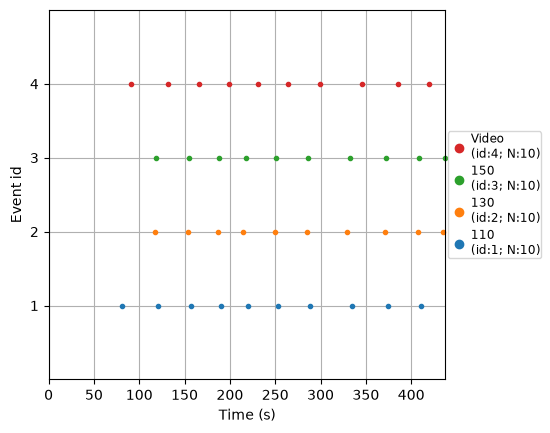

In [53]:
events, event_dict = mne.events_from_annotations(raw_haemo, verbose=False)
mne.viz.plot_events(events, event_id=event_dict, sfreq=raw_haemo.info['sfreq']);



In [54]:
def _update_designmatrix(df):
    """
    Label trials for an LSA model.

    Parameters:
    - df: DataFrame containing trial information.

    Returns:
    - df: Updated DataFrame with labeled trial types.
    """

    unique_conditions = df["trial_type"].unique()

    df["class"] = df["trial_type"]
    condition_counter = {condition: 0 for condition in unique_conditions}

    for i, trial in df.iterrows():
        trial_condition = trial["class"]
        condition_counter[trial_condition] += 1
        labeled_trial_name = f"{trial_condition}_{condition_counter[trial_condition]:03d}"
        df.loc[i, "trial_type"] = labeled_trial_name

    return df

In [200]:
# for each event in annotation, get onset
# get duration
# get description
# create a dataframe with onset, duration and description

df = pd.DataFrame(raw_haemo.annotations)

df = df.rename(columns={"onset": "onset", "duration": "duration", "description": "trial_type"})

# drop column orig
df = df.drop(columns="orig_time")

df.head(10)



,onset,duration,trial_type
0,23.01440,7.5,M1
1,31.02976,7.5,M1
2,39.04512,7.5,M1
3,47.06048,7.5,Baseline
4,63.01184,7.5,M2
5,71.02720,7.5,M2
6,79.04256,7.5,M2
7,87.05792,7.5,Baseline
8,103.08864,7.5,M4
9,111.10400,7.5,M4


In [201]:
# Events to dataframe.


# Update the design matrix.
events_df_lsa = _update_designmatrix(df)

events_df_lsa.head()



,onset,duration,trial_type,class
0,23.01440,7.5,M1_001,M1
1,31.02976,7.5,M1_002,M1
2,39.04512,7.5,M1_003,M1
3,47.06048,7.5,Baseline_001,Baseline
4,63.01184,7.5,M2_001,M2


In [202]:
events_df_lsa

,onset,duration,trial_type,class
0,23.01440,7.5,M1_001,M1
1,31.02976,7.5,M1_002,M1
2,39.04512,7.5,M1_003,M1
3,47.06048,7.5,Baseline_001,Baseline
4,63.01184,7.5,M2_001,M2
5,71.02720,7.5,M2_002,M2
6,79.04256,7.5,M2_003,M2
7,87.05792,7.5,Baseline_002,Baseline
8,103.08864,7.5,M4_001,M4
9,111.10400,7.5,M4_002,M4


In [203]:
# create frame_times
frame_times = raw_haemo.times

print(frame_times)

[0.000000e+00 7.940000e-02 1.588000e-01 ... 1.790470e+02 1.791264e+02
 1.792058e+02]


In [204]:



design_matrix = make_first_level_design_matrix(frame_times, 
                                               events_df_lsa,
                                               drift_model='polynomial',
                                               high_pass=0.005,  # Must be specified per experiment
                                               hrf_model='spm')


# Remove Baseline from design matrix
# design_matrix = design_matrix.drop(columns=['Baseline'])

# Add columns for the events_df_lsa columns






/opt/anaconda3/envs/MNE-NIRS/lib/python3.12/site-packages/nilearn/glm/first_level/experimental_paradigm.py:167: UserWarning: The following unexpected columns in events data will be ignored: class
  warnings.warn(


### 3.1.2 Short channels

In [ ]:

# Add short channels to the design matrix
short_ch_names =  short_haemo.ch_names

# for each name in shortch_names
for name in short_ch_names:

    # get the data from the short channel    
    design_matrix[name] = short_haemo.copy().pick(picks=name).get_data().transpose()

### 3.1.3 Add auxiliary data - physio

In [ ]:
import h5py
from scipy import interpolate

fname = snirf_file[0]


In [ ]:
def _decode_name(key):
    return np.array(key).astype(str)

In [ ]:
def _get_data_idx(timeseries, t_ref):
    """Get the index of the closest time point in the timeseries."""
    return np.argmin(np.abs(timeseries - t_ref))

In [ ]:
def _trim_aux_data(aux_data, init_idx, end_idx):
    """Trim the auxiliary data to the specified time window."""
    if aux_data is None:
        return None
    else:
        return aux_data[init_idx:end_idx]
    

In [ ]:
with h5py.File(fname, "r") as dat:
        if "nirs" in dat:
            basename = "nirs"
        elif "nirs1" in dat:
            basename = "nirs1"
        else:
            raise RuntimeError("Data does not contain nirs field")

        all_keys = list(dat.get(basename).keys())
        aux_keys = [i for i in all_keys if i.startswith("aux")]

        aux_names = [_decode_name(dat.get(f"{basename}/{k}/name")) for k in aux_keys]

        d = {"times": raw_haemo.times}
        for idx, aux in enumerate(aux_keys):
            aux_data = np.array(dat.get(f"{basename}/{aux}/dataTimeSeries"))
            aux_time = np.array(dat.get(f"{basename}/{aux}/time"))

            # print(aux_data.shape)
            trim_idx_init = _get_data_idx(aux_time, tmin)
            trim_idx_end = _get_data_idx(aux_time, tmax)

            aux_data = _trim_aux_data(aux_data, trim_idx_init, trim_idx_end)   
            aux_time = _trim_aux_data(aux_time, trim_idx_init, trim_idx_end)

            aux_data_interp = interpolate.interp1d(
                aux_time, aux_data, axis=0, bounds_error=False, fill_value="extrapolate"
            )
            aux_data_matched_to_raw = aux_data_interp(raw_haemo.times)
            
            # print(aux_data_matched_to_raw.ndim)

            # Remove single dimension
            if aux_data_matched_to_raw.ndim == 2:
                aux_data_matched_to_raw = aux_data_matched_to_raw[:,0]
            
            d[str(aux_names[idx])] = aux_data_matched_to_raw


        df = pd.DataFrame(data=d)
        df = df.set_index("times")

   

In [ ]:
df

,ACCEL_X_1,ExGa4,ECG,Respiration,PPG,SpO2,Heartrate,GSR,Temperature,ACCEL_Y_1,ACCEL_Z_1,GYRO_X_1,GYRO_Y_1,GYRO_Z_1,ExGa1,ExGa2,ExGa3
times,,,,,,,,,,,,,,,,,
0.0000,7.514151,34.909919,-0.013624,107.884399,16.157999,100.0,63.0,23.500649,22.8125,-1.551678,12.263771,-94.805418,-0.366000,112.081701,-0.009716,21.767712,63.463083
0.0794,7.337314,33.990657,-0.013192,107.884399,16.157999,100.0,63.0,23.360458,22.8125,-1.768706,11.894020,-92.353808,-0.366000,109.139770,-0.009504,21.194256,61.791026
0.1588,7.160477,33.071395,-0.012761,107.884399,16.157999,100.0,63.0,23.220267,22.8125,-1.985733,11.524269,-89.902199,-0.366000,106.197838,-0.009292,20.620800,60.118968
0.2382,6.983639,32.152133,-0.012329,107.884399,16.157999,100.0,63.0,23.080077,22.8125,-2.202761,11.154518,-87.450589,-0.366000,103.255907,-0.009080,20.047344,58.446911
0.3176,6.806802,31.232871,-0.011897,107.884399,16.157999,100.0,63.0,22.939886,22.8125,-2.419789,10.784767,-84.998979,-0.366000,100.313975,-0.008868,19.473888,56.774854
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178.8882,1.303490,-0.009930,0.003541,105.614838,16.421000,100.0,72.0,18.489676,22.7500,-9.758541,-1.541331,-0.851864,-0.367555,1.275778,-0.002431,-0.009961,-0.015669
178.9676,1.361478,-0.013791,0.003521,105.591911,16.304001,100.0,72.0,18.502906,22.7500,-9.711191,-1.550000,-0.421172,-0.979914,-0.793000,-0.002439,-0.011974,-0.016984
179.0470,1.412208,-0.017498,0.003186,105.591911,16.195000,100.0,72.0,18.512893,22.7500,-9.690931,-1.529307,0.427000,-0.532083,-0.361771,-0.002442,-0.013998,-0.018173


In [ ]:
design_matrix.shape

(2258, 82)

In [ ]:

# Add physio data in df to the design matrix
design_matrix = design_matrix.join(df, how='outer')

design_matrix


,Baseline_001,Baseline_002,Baseline_003,Baseline_004,M1_001,M1_002,M1_003,M2_001,M2_002,M2_003,...,GSR,Temperature,ACCEL_Y_1,ACCEL_Z_1,GYRO_X_1,GYRO_Y_1,GYRO_Z_1,ExGa1,ExGa2,ExGa3
0.0000,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,23.500649,22.8125,-1.551678,12.263771,-94.805418,-0.366000,112.081701,-0.009716,21.767712,63.463083
0.0794,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,23.360458,22.8125,-1.768706,11.894020,-92.353808,-0.366000,109.139770,-0.009504,21.194256,61.791026
0.1588,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,23.220267,22.8125,-1.985733,11.524269,-89.902199,-0.366000,106.197838,-0.009292,20.620800,60.118968
0.2382,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,23.080077,22.8125,-2.202761,11.154518,-87.450589,-0.366000,103.255907,-0.009080,20.047344,58.446911
0.3176,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,...,22.939886,22.8125,-2.419789,10.784767,-84.998979,-0.366000,100.313975,-0.008868,19.473888,56.774854
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
178.8882,0.0,0.0,0.0,0.638039,0.0,0.0,0.0,0.0,0.0,0.0,...,18.489676,22.7500,-9.758541,-1.541331,-0.851864,-0.367555,1.275778,-0.002431,-0.009961,-0.015669
178.9676,0.0,0.0,0.0,0.620846,0.0,0.0,0.0,0.0,0.0,0.0,...,18.502906,22.7500,-9.711191,-1.550000,-0.421172,-0.979914,-0.793000,-0.002439,-0.011974,-0.016984
179.0470,0.0,0.0,0.0,0.603669,0.0,0.0,0.0,0.0,0.0,0.0,...,18.512893,22.7500,-9.690931,-1.529307,0.427000,-0.532083,-0.361771,-0.002442,-0.013998,-0.018173
179.1264,0.0,0.0,0.0,0.586529,0.0,0.0,0.0,0.0,0.0,0.0,...,18.527605,22.7500,-9.752479,-1.503806,0.299493,0.610000,0.127507,-0.002442,-0.016411,-0.019788


### 3.1.4 Plotting the design matrix

/opt/anaconda3/envs/MNE-NIRS/lib/python3.12/site-packages/nilearn/plotting/matrix_plotting.py:503: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


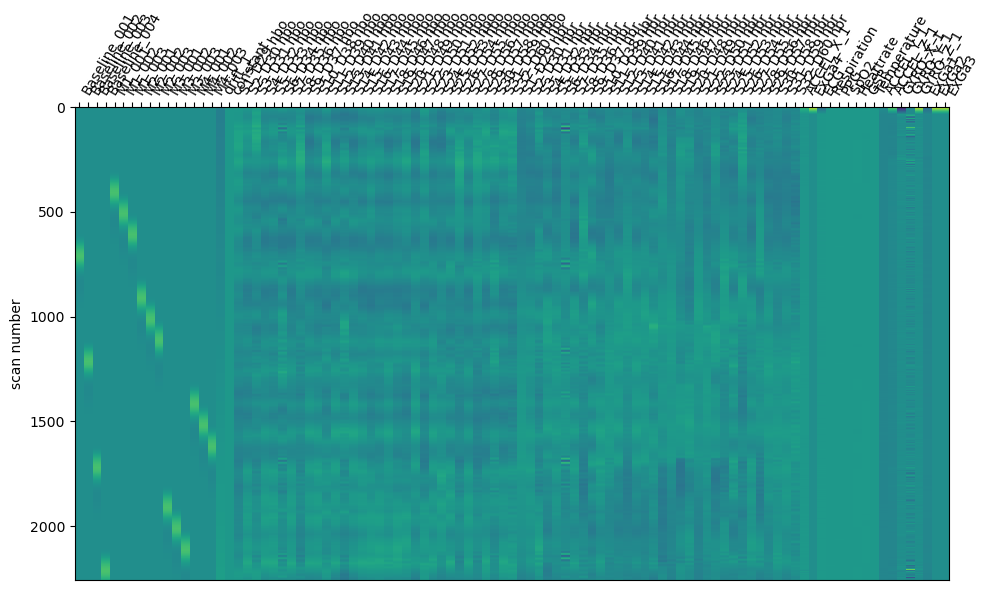

In [ ]:
from nilearn.plotting import plot_design_matrix

fig, ax1 = plt.subplots(figsize=(10, 6), constrained_layout=True)
fig = plot_design_matrix(design_matrix, ax=ax1)


Used Annotations descriptions: ['Baseline', 'M1', 'M2', 'M3', 'M4']


[Text(0.5, 0, 'Time (s)'), Text(0, 0.5, 'Amplitude')]

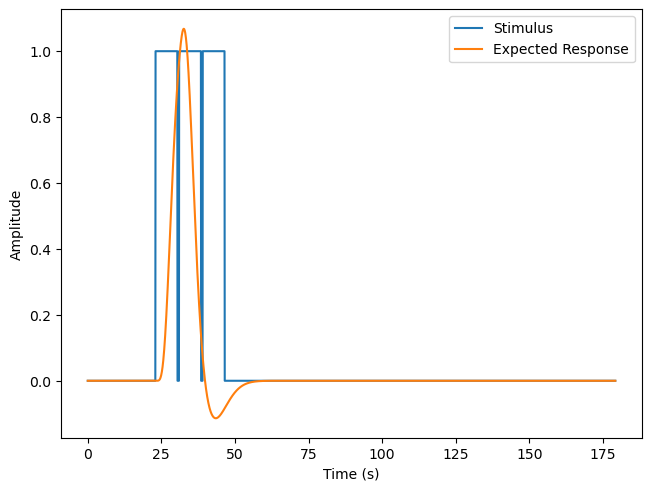

In [ ]:
fig, ax = plt.subplots(constrained_layout=True)

s = mne_nirs.experimental_design.create_boxcar(raw_intensity, stim_dur=7.5)

ax.plot(raw_intensity.times, s[:, 1])
ax.plot(design_matrix['M1_001'])
ax.legend(["Stimulus", "Expected Response"])
ax.set( xlabel="Time (s)", ylabel="Amplitude")

## 3.2 Fit GLM to data and estimate response for Music experimental condition

In [ ]:
long_haemo

Measurement date,"August 05, 2024 13:43:28 GMT"
Experimenter,Unknown
Participant,
Digitized points,300 points
Good channels,"95 Oxyhemoglobin, 95 Deoxyhemoglobin"
Bad channels,"S9_D5 hbo, S9_D7 hbo, S9_D23 hbo, S9_D5 hbr, S9_D7 hbr, S9_D23 hbr"
EOG channels,Not available
ECG channels,Not available
Sampling frequency,12.59 Hz
Highpass,0.00 Hz
Lowpass,0.50 Hz


In [ ]:
from mne_nirs.statistics import run_glm

glm_est = run_glm(long_haemo, design_matrix, noise_model='ar1') # ar(1)


In [ ]:

df_glm = glm_est.to_dataframe()



In [ ]:
# rows of the dataframe with the condition M_001 and M_002 and M_003 or Baseline and ch_name contains hbo without using query

df_glm_M = df_glm.query('Condition in ["M1_001"] and ch_name.str.contains("hbo")', engine='python')


In [ ]:
df_glm_M

variable,Condition,df,mse,p_value,se,t,theta,Source,Detector,Chroma,Significant,ch_name
6353,M1_001,99.0,1.059482e-17,2.223804e-07,2.147864e-08,5.566796,1.195672e-07,1,1,hbo,True,S1_D1 hbo
6551,M1_001,99.0,4.047165e-18,1.803306e-16,1.327503e-08,9.900502,1.314295e-07,1,2,hbo,True,S1_D2 hbo
6749,M1_001,99.0,1.105603e-17,3.128711e-06,2.194116e-08,4.943819,1.084731e-07,1,28,hbo,True,S1_D28 hbo
13481,M1_001,99.0,4.848849e-18,8.132638e-10,1.453046e-08,-6.796704,-9.875924e-08,2,1,hbo,True,S2_D1 hbo
13679,M1_001,99.0,9.843138e-18,4.195812e-36,2.070269e-08,19.743478,4.087432e-07,2,2,hbo,True,S2_D2 hbo
...,...,...,...,...,...,...,...,...,...,...,...,...
14273,M1_001,99.0,3.351189e-18,5.183906e-19,1.258785e-08,11.068674,1.393308e-07,31,2,hbo,True,S31_D2 hbo
14471,M1_001,99.0,1.716733e-17,7.233381e-03,2.734081e-08,-2.742714,-7.498803e-08,31,27,hbo,True,S31_D27 hbo
14669,M1_001,99.0,9.176047e-18,5.584334e-08,2.082955e-08,-5.879292,-1.224630e-07,31,28,hbo,True,S31_D28 hbo
14867,M1_001,99.0,2.187062e-17,9.655756e-28,2.975539e-08,-15.254731,-4.539104e-07,32,27,hbo,True,S32_D27 hbo


Text(0, 0.5, 't-value')

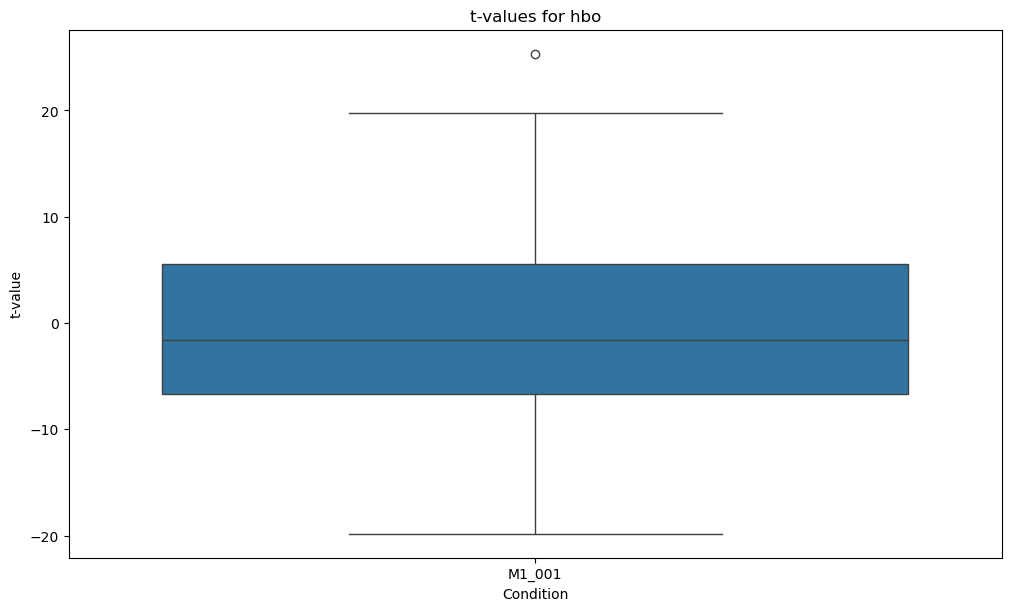

In [ ]:
# plot boxplot of the df_glm_M t values using seaborn using Condition as x
import seaborn as sns

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
sns.boxplot(data=df_glm_M, x='Condition', y='t', ax=ax)
ax.set_title('t-values for hbo')
ax.set_ylabel('t-value')


In [ ]:
# sort channels by t-value
df_glm_M_sorted = df_glm_M.sort_values(by='t', ascending=False)

# get the top 5 channels
top_channels = df_glm_M_sorted.ch_name.unique()[:10]

df_glm_M_sorted

variable,Condition,df,mse,p_value,se,t,theta,Source,Detector,Chroma,Significant,ch_name
15659,M1_001,99.0,4.788020e-18,4.633556e-45,1.443903e-08,25.334685,3.658083e-07,4,2,hbo,True,S4_D2 hbo
13679,M1_001,99.0,9.843138e-18,4.195812e-36,2.070269e-08,19.743478,4.087432e-07,2,2,hbo,True,S2_D2 hbo
3383,M1_001,99.0,3.955292e-18,5.792780e-33,1.367544e-08,17.987374,2.459853e-07,15,10,hbo,True,S15_D10 hbo
16055,M1_001,99.0,2.273909e-18,2.317387e-31,1.036904e-08,17.125779,1.775779e-07,4,3,hbo,True,S4_D3 hbo
15461,M1_001,99.0,2.687689e-16,1.458916e-29,1.043097e-07,16.183481,1.688093e-06,3,4,hbo,True,S3_D4 hbo
...,...,...,...,...,...,...,...,...,...,...,...,...
14867,M1_001,99.0,2.187062e-17,9.655756e-28,2.975539e-08,-15.254731,-4.539104e-07,32,27,hbo,True,S32_D27 hbo
7343,M1_001,99.0,7.021985e-18,7.112369e-30,1.582275e-08,-16.345089,-2.586242e-07,20,17,hbo,True,S20_D17 hbo
7541,M1_001,99.0,4.088584e-18,6.858495e-31,1.286535e-08,-16.876463,-2.171216e-07,21,18,hbo,True,S21_D18 hbo
17837,M1_001,99.0,2.553917e-18,1.269568e-31,1.152845e-08,-17.264837,-1.990368e-07,7,7,hbo,True,S7_D7 hbo


In [ ]:
list_top_channels =top_channels.tolist()

list_top_channels

['S4_D2 hbo',
 'S2_D2 hbo',
 'S15_D10 hbo',
 'S4_D3 hbo',
 'S3_D4 hbo',
 'S12_D10 hbo',
 'S29_D25 hbo',
 'S12_D9 hbo',
 'S4_D26 hbo',
 'S31_D2 hbo']

In [ ]:
# Fit GLM to all data and view topographic distribution

# glm_est.pick(picks=list_top_channels).plot_topo(conditions='M_001',vmin=-10, vmax=10);


In [ ]:
# glm_est.copy().surface_projection(condition="M", view="dorsal", chroma="hbo")

# 4. Save data

In [ ]:
from mne_nirs.io import write_raw_snirf


# write data_path using p_id.
derivatives_data_path = os.path.join('..', 'data', 'dataset', 'derivatives', 'mne-nirs', p_id)

if not os.path.exists(derivatives_data_path):
    os.makedirs(derivatives_data_path)

print(derivatives_data_path)

# save glm results to a file
df_glm.to_csv(os.path.join(derivatives_data_path, f'sub-{p_id}_run-{run_id}_glm_lsa.csv'))


# write_raw_snirf(long_haemo, os.path.join(derivatives_data_path, f'{p_id}_{run_id}_long_haemo.snirf'))

../data/dataset/derivatives/mne-nirs/S10


In [ ]:
# save long_haemo to file
long_haemo.save(os.path.join(derivatives_data_path, f'sub-{p_id}_run-{run_id}_long_haemo.fif'), overwrite=True)

Writing /Users/brunomiguel/Documents/GitHub/NIRS-pytools/scripts/../data/dataset/derivatives/mne-nirs/S10/sub-S10_run-1_long_haemo.fif
Closing /Users/brunomiguel/Documents/GitHub/NIRS-pytools/scripts/../data/dataset/derivatives/mne-nirs/S10/sub-S10_run-1_long_haemo.fif
[done]


/var/folders/d_/lr6pgxv95sgf0gw5zh_09rs40000gn/T/ipykernel_49864/3573592471.py:2: RuntimeWarning: This filename (/Users/brunomiguel/Documents/GitHub/NIRS-pytools/scripts/../data/dataset/derivatives/mne-nirs/S10/sub-S10_run-1_long_haemo.fif) does not conform to MNE naming conventions. All raw files should end with raw.fif, raw_sss.fif, raw_tsss.fif, _meg.fif, _eeg.fif, _ieeg.fif, raw.fif.gz, raw_sss.fif.gz, raw_tsss.fif.gz, _meg.fif.gz, _eeg.fif.gz or _ieeg.fif.gz
  long_haemo.save(os.path.join(derivatives_data_path, f'sub-{p_id}_run-{run_id}_long_haemo.fif'), overwrite=True)
